In [1]:
# Cell 1: Imports and project configuration

from pathlib import Path
import os
import sys
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Main project directory
PROJECT_ROOT = Path(
    os.environ.get(
        "WCNC_PROJECT_ROOT",
        "/home/afanali/wcnc_project"
    )
)

RESULTS_DIR = PROJECT_ROOT / "improved_experiment_v2" / "results"
FIGURES_DIR = PROJECT_ROOT / "improved_experiment_v2" / "figures_three_agents"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Main saved prediction summary
SUMMARY_FILE = RESULTS_DIR / "forecaster_loto_summary.json"

print("Project root:", PROJECT_ROOT)
print("Results directory:", RESULTS_DIR)
print("Summary file exists:", SUMMARY_FILE.exists())
print("Figures directory:", FIGURES_DIR)

Project root: /home/afanali/wcnc_project
Results directory: /home/afanali/wcnc_project/improved_experiment_v2/results
Summary file exists: True
Figures directory: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents


In [2]:
# Cell 2: Load saved predictions and targets from the main notebook

with open(SUMMARY_FILE, "r", encoding="utf-8") as f:
    forecast_summary = json.load(f)

NUM_FOLDS = int(forecast_summary["num_folds"])

MODELS = [
    "persistence",
    "deterministic",
    "independent",
    "joint",
    "hurdle_joint",
]

fold_data = {}

for fold in range(NUM_FOLDS):
    fold_file = RESULTS_DIR / f"fold_{fold}_summary_predictions.npz"

    if not fold_file.exists():
        raise FileNotFoundError(f"Missing fold file: {fold_file}")

    with np.load(fold_file, allow_pickle=True) as data:
        fold_data[fold] = {
            key: data[key].copy()
            for key in data.files
        }

print(f"Loaded {len(fold_data)} LOTO folds.")
print("Models:", MODELS)
print("First-fold keys:")
print(sorted(fold_data[0].keys()))

print("\nImportant array shapes:")
for key in [
    "test_target_db",
    "test_Yv",
    "test_observed_power_db",
]:
    print(f"{key}: {fold_data[0][key].shape}")

Loaded 6 LOTO folds.
Models: ['persistence', 'deterministic', 'independent', 'joint', 'hurdle_joint']
First-fold keys:
['gnb_names', 'test_Yv', 'test_best', 'test_deterministic_mean_db', 'test_hurdle_joint_link_prob', 'test_hurdle_joint_mean_db', 'test_hurdle_joint_std_db', 'test_independent_mean_db', 'test_independent_std_db', 'test_joint_mean_db', 'test_joint_std_db', 'test_observed_power_db', 'test_persistence_mean_db', 'test_target_db', 'val_Yv', 'val_best', 'val_deterministic_mean_db', 'val_hurdle_joint_link_prob', 'val_hurdle_joint_mean_db', 'val_hurdle_joint_std_db', 'val_independent_mean_db', 'val_independent_std_db', 'val_joint_mean_db', 'val_joint_std_db', 'val_observed_power_db', 'val_persistence_mean_db', 'val_target_db']

Important array shapes:
test_target_db: (223, 6, 5)
test_Yv: (223, 6, 5)
test_observed_power_db: (223, 5)


In [3]:
# Cell 3: Common data interface for all forecasters

from dataclasses import dataclass
from typing import Optional


@dataclass
class ForecastBatch:
    """
    Forecast output for one model across all decision windows.

    Shape of mean_db:
        [number_of_windows, forecast_horizon, number_of_gnbs]
    """
    mean_db: np.ndarray
    std_db: Optional[np.ndarray] = None
    link_prob: Optional[np.ndarray] = None


def optional_key(data, key):
    """Return an array if the key exists; otherwise return None."""
    return data[key] if key in data else None


def load_forecast_batches(fold_index, split="test"):
    """
    Load all forecaster outputs for one LOTO fold.

    split can be 'val' or 'test'.
    """
    data = fold_data[fold_index]
    batches = {}

    for model in MODELS:
        mean_key = f"{split}_{model}_mean_db"

        if mean_key not in data:
            raise KeyError(f"Missing required key: {mean_key}")

        batches[model] = ForecastBatch(
            mean_db=data[mean_key],
            std_db=optional_key(
                data,
                f"{split}_{model}_std_db"
            ),
            link_prob=optional_key(
                data,
                f"{split}_{model}_link_prob"
            ),
        )

    return batches


def load_fold_inputs(fold_index, split="test"):
    """Load targets, validity masks, and observed power for one fold."""
    data = fold_data[fold_index]

    return {
        "forecasts": load_forecast_batches(fold_index, split),
        "target_db": data[f"{split}_target_db"],
        "valid": data[f"{split}_Yv"].astype(bool),
        "observed_power_db": data[f"{split}_observed_power_db"],
        "gnb_names": data["gnb_names"].astype(str).tolist(),
    }


# Test the interface on fold 0
fold0_test = load_fold_inputs(0, split="test")

print("gNBs:", fold0_test["gnb_names"])
print("Target shape:", fold0_test["target_db"].shape)
print("Validity shape:", fold0_test["valid"].shape)
print("Observed power shape:", fold0_test["observed_power_db"].shape)

for model, output in fold0_test["forecasts"].items():
    print(
        f"{model:15s} | mean={output.mean_db.shape} | "
        f"std={None if output.std_db is None else output.std_db.shape} | "
        f"prob={None if output.link_prob is None else output.link_prob.shape}"
    )

gNBs: ['gNB1_B59', 'gNB2_Building_44', 'gNB3_Building_54', 'gNB4_Building_29_Community_Center', 'gNB5_Building_617']
Target shape: (223, 6, 5)
Validity shape: (223, 6, 5)
Observed power shape: (223, 5)
persistence     | mean=(223, 6, 5) | std=None | prob=None
deterministic   | mean=(223, 6, 5) | std=None | prob=None
independent     | mean=(223, 6, 5) | std=(223, 6, 5) | prob=None
joint           | mean=(223, 6, 5) | std=(223, 6, 5) | prob=None
hurdle_joint    | mean=(223, 6, 5) | std=(223, 6, 5) | prob=(223, 6, 5)


In [4]:
# Cell 4: Shared runtime state and validation forecasting scores

from dataclasses import dataclass, field


@dataclass
class RuntimeState:
    """State shared by the forecasting, planning, and adaptation agents."""

    serving_gnb: int
    reliability: np.ndarray
    forecast_weights: dict = field(default_factory=dict)
    forecast_scores: dict = field(default_factory=dict)

    # TTT persistence state
    ttt_target: Optional[int] = None
    ttt_streak: int = 0

    # Recent runtime feedback
    recent_failure: float = 0.0
    recent_switch: float = 0.0

    # Current decision information
    selected_model: str = ""
    forecast_regime: str = "stable"
    step: int = 0


def masked_mae_db(prediction, target, valid):
    """Compute MAE only on valid ray-traced links."""
    prediction = np.asarray(prediction, dtype=float)
    target = np.asarray(target, dtype=float)
    valid = np.asarray(valid, dtype=bool)

    mask = (
        valid
        & np.isfinite(prediction)
        & np.isfinite(target)
    )

    if not np.any(mask):
        return np.nan

    return float(np.mean(np.abs(
        prediction[mask] - target[mask]
    )))


def initialize_runtime_state(observed_power_db):
    """
    Initialize the runtime state using the strongest currently observed gNB.
    """
    number_of_gnbs = observed_power_db.shape[-1]
    serving_gnb = int(np.argmax(observed_power_db[0]))

    equal_weights = {
        model: 1.0 / len(MODELS)
        for model in MODELS
    }

    return RuntimeState(
        serving_gnb=serving_gnb,
        reliability=np.ones(number_of_gnbs, dtype=float),
        forecast_weights=equal_weights.copy(),
        forecast_scores={model: np.nan for model in MODELS},
    )


# Compute validation-only MAE priors.
# These values initialize the Forecasting Agent without using test data.
validation_mae_by_fold = {}

for fold in range(NUM_FOLDS):
    validation_data = load_fold_inputs(fold, split="val")

    validation_mae_by_fold[fold] = {}

    for model, output in validation_data["forecasts"].items():
        validation_mae_by_fold[fold][model] = masked_mae_db(
            output.mean_db,
            validation_data["target_db"],
            validation_data["valid"],
        )

print("Validation MAE priors for fold 0:")
for model, value in validation_mae_by_fold[0].items():
    print(f"{model:15s}: {value:.3f} dB")

state0 = initialize_runtime_state(
    fold0_test["observed_power_db"]
)

print("\nInitial serving gNB:", state0.serving_gnb)
print("Initial reliability:", state0.reliability)
print("Initial forecast weights:", state0.forecast_weights)

Validation MAE priors for fold 0:
persistence    : 18.445 dB
deterministic  : 14.359 dB
independent    : 15.316 dB
joint          : 16.713 dB
hurdle_joint   : 7.625 dB

Initial serving gNB: 4
Initial reliability: [1. 1. 1. 1. 1.]
Initial forecast weights: {'persistence': 0.2, 'deterministic': 0.2, 'independent': 0.2, 'joint': 0.2, 'hurdle_joint': 0.2}


In [5]:
# Cell 5: Forecasting Agent

class ForecastingAgent:
    """
    Selects the most suitable forecaster for the current situation.

    The agent does not retrain the GRUs online. Instead, it updates model
    scores and weights using validation priors and causal execution feedback.
    """

    def __init__(
        self,
        model_names,
        validation_scores,
        ema_decay=0.8,
        temperature=1.0,
        availability_weight=5.0,
    ):
        self.model_names = list(model_names)
        self.ema_decay = ema_decay
        self.temperature = temperature
        self.availability_weight = availability_weight

        # Separate scores for stable and unstable propagation regimes
        self.scores = {
            "stable": {
                model: float(validation_scores[model])
                for model in self.model_names
            },
            "unstable": {
                model: float(validation_scores[model])
                for model in self.model_names
            },
        }

    @staticmethod
    def _softmax_negative(scores, temperature=1.0):
        names = list(scores.keys())
        values = -np.asarray(
            [scores[name] for name in names],
            dtype=float,
        )

        values = values / max(temperature, 1e-6)
        values = values - np.max(values)

        weights = np.exp(values)
        weights = weights / np.sum(weights)

        return {
            name: float(weight)
            for name, weight in zip(names, weights)
        }

    @staticmethod
    def _get_regime(current_valid, reliability):
        """
        Classify the current situation as stable or unstable.
        """
        if current_valid is not None:
            valid_fraction = np.mean(current_valid)

            if valid_fraction < 0.8:
                return "unstable"

        if np.mean(reliability) < 0.85:
            return "unstable"

        return "stable"

    def select(self, forecasts_at_t, current_valid, state):
        """
        Select one forecaster at the current decision epoch.

        forecasts_at_t contains one ForecastBatch per model with shape:
            mean_db: [forecast_horizon, number_of_gnbs]
        """

        regime = self._get_regime(
            current_valid=current_valid,
            reliability=state.reliability,
        )

        available_models = [
            model
            for model in self.model_names
            if model in forecasts_at_t
        ]

        scores = {
            model: self.scores[regime][model]
            for model in available_models
        }

        weights = self._softmax_negative(
            scores,
            temperature=self.temperature,
        )

        selected_model = max(
            weights,
            key=weights.get,
        )

        state.selected_model = selected_model
        state.forecast_regime = regime
        state.forecast_weights = weights
        state.forecast_scores = scores

        return {
            "model": selected_model,
            "forecast": forecasts_at_t[selected_model],
            "weights": weights,
            "scores": scores,
            "regime": regime,
        }

    def update_from_observation(
        self,
        forecasts_at_previous_step,
        observed_power_db,
        observed_valid,
        state,
    ):
        """
        Update model scores after the next observation is available.

        Only the first predicted step is evaluated. This keeps the update
        causal during route replay.
        """

        observed_power_db = np.asarray(
            observed_power_db,
            dtype=float,
        )

        observed_valid = np.asarray(
            observed_valid,
            dtype=bool,
        )

        regime = self._get_regime(
            current_valid=observed_valid,
            reliability=state.reliability,
        )

        for model in self.model_names:
            if model not in forecasts_at_previous_step:
                continue

            forecast = forecasts_at_previous_step[model]

            prediction = np.asarray(
                forecast.mean_db[0],
                dtype=float,
            )

            valid_mask = (
                observed_valid
                & np.isfinite(observed_power_db)
                & np.isfinite(prediction)
            )

            losses = []

            # Masked path-power error
            if np.any(valid_mask):
                power_mae = np.mean(
                    np.abs(
                        prediction[valid_mask]
                        - observed_power_db[valid_mask]
                    )
                )
                losses.append(float(power_mae))

            # Availability calibration error, when provided
            if forecast.link_prob is not None:
                probability = np.clip(
                    np.asarray(forecast.link_prob[0], dtype=float),
                    0.0,
                    1.0,
                )

                brier_error = np.mean(
                    (
                        probability
                        - observed_valid.astype(float)
                    ) ** 2
                )

                losses.append(
                    self.availability_weight * float(brier_error)
                )

            if not losses:
                continue

            new_loss = float(np.mean(losses))
            old_loss = self.scores[regime][model]

            self.scores[regime][model] = (
                self.ema_decay * old_loss
                + (1.0 - self.ema_decay) * new_loss
            )

        state.forecast_regime = regime
        state.forecast_weights = self._softmax_negative(
            self.scores[regime],
            temperature=self.temperature,
        )


def forecasts_at_epoch(forecast_batches, epoch):
    """
    Extract one decision epoch from the saved forecast arrays.
    """
    outputs = {}

    for model, batch in forecast_batches.items():
        outputs[model] = ForecastBatch(
            mean_db=batch.mean_db[epoch],
            std_db=(
                None
                if batch.std_db is None
                else batch.std_db[epoch]
            ),
            link_prob=(
                None
                if batch.link_prob is None
                else batch.link_prob[epoch]
            ),
        )

    return outputs


# Test the Forecasting Agent on the first decision epoch
fold0_val = load_fold_inputs(0, split="val")

forecasting_agent = ForecastingAgent(
    model_names=MODELS,
    validation_scores=validation_mae_by_fold[0],
)

forecast_state = initialize_runtime_state(
    fold0_val["observed_power_db"]
)

forecasts_epoch0 = forecasts_at_epoch(
    fold0_val["forecasts"],
    epoch=0,
)

forecast_selection = forecasting_agent.select(
    forecasts_at_t=forecasts_epoch0,
    current_valid=None,
    state=forecast_state,
)

print("Selected model:", forecast_selection["model"])
print("Situation:", forecast_selection["regime"])
print("Forecast weights:")

for model, weight in forecast_selection["weights"].items():
    print(f"  {model:15s}: {weight:.3f}")

Selected model: hurdle_joint
Situation: stable
Forecast weights:
  persistence    : 0.000
  deterministic  : 0.001
  independent    : 0.000
  joint          : 0.000
  hurdle_joint   : 0.998


In [6]:
# Cell 6: Planning Agent

FLOOR_DB = -220.0


class PlanningAgent:
    """
    Risk-aware finite-horizon planning agent.

    The agent uses the selected forecast, uncertainty, link availability,
    runtime reliability, and TTT state to choose the next action.
    """

    def __init__(
        self,
        base_beta=0.5,
        base_handover_cost_db=2.0,
        base_failure_penalty_db=2.0,
        base_ttt=2,
        min_ttt=1,
        max_ttt=3,
    ):
        self.base_beta = base_beta
        self.base_handover_cost_db = base_handover_cost_db
        self.base_failure_penalty_db = base_failure_penalty_db
        self.base_ttt = base_ttt
        self.min_ttt = min_ttt
        self.max_ttt = max_ttt

    @staticmethod
    def risk_aware_scores(
        mean_db,
        std_db,
        link_prob,
        beta,
        failure_penalty_db,
        reliability,
    ):
        """
        Compute risk-aware future link scores.
        """

        mean_db = np.asarray(mean_db, dtype=float)
        horizon, number_of_gnbs = mean_db.shape

        if std_db is None:
            std_db = np.zeros_like(mean_db)
        else:
            std_db = np.asarray(std_db, dtype=float)

        if link_prob is None:
            link_prob = np.ones_like(mean_db)
        else:
            link_prob = np.asarray(link_prob, dtype=float)

        reliability = np.asarray(
            reliability,
            dtype=float,
        ).reshape(1, number_of_gnbs)

        # Effective probability of a usable link
        effective_probability = np.clip(
            link_prob * reliability,
            1e-4,
            1.0,
        )

        # Conservative power estimate
        conservative_power_db = (
            mean_db - beta * std_db
        )

        conservative_power_linear = 10 ** (
            np.clip(
                conservative_power_db,
                FLOOR_DB,
                0.0,
            ) / 10.0
        )

        floor_linear = 10 ** (FLOOR_DB / 10.0)

        expected_power_linear = (
            effective_probability
            * conservative_power_linear
            + (
                1.0 - effective_probability
            )
            * floor_linear
        )

        scores_db = 10 * np.log10(
            np.maximum(
                expected_power_linear,
                floor_linear,
            )
        )

        # Explicit invalid-link risk penalty
        scores_db -= (
            failure_penalty_db
            * (1.0 - effective_probability)
        )

        return scores_db

    @staticmethod
    def dynamic_programming_action(
        step_scores,
        current_gnb,
        handover_cost_db,
    ):
        """
        Select the first action using finite-horizon dynamic programming.
        """

        step_scores = np.asarray(
            step_scores,
            dtype=float,
        )

        horizon, number_of_gnbs = step_scores.shape

        future_value = np.zeros(
            number_of_gnbs,
            dtype=float,
        )

        first_action = None

        for h in range(horizon - 1, -1, -1):
            current_value = np.full(
                number_of_gnbs,
                -np.inf,
            )

            current_policy = np.zeros(
                number_of_gnbs,
                dtype=int,
            )

            for previous_gnb in range(number_of_gnbs):
                candidate_values = []

                for candidate_gnb in range(number_of_gnbs):
                    switching_cost = (
                        handover_cost_db
                        if candidate_gnb != previous_gnb
                        else 0.0
                    )

                    candidate_values.append(
                        step_scores[h, candidate_gnb]
                        - switching_cost
                        + future_value[candidate_gnb]
                    )

                best_candidate = int(
                    np.argmax(candidate_values)
                )

                current_policy[previous_gnb] = best_candidate
                current_value[previous_gnb] = (
                    candidate_values[best_candidate]
                )

            if h == 0:
                first_action = current_policy

            future_value = current_value

        return (
            int(first_action[current_gnb]),
            float(future_value[current_gnb]),
        )

    @staticmethod
    def apply_ttt(
        recommendation,
        ttt_k,
        state,
    ):
        """
        Apply TTT persistence before changing the serving gNB.
        """

        recommendation = int(recommendation)

        if recommendation == state.serving_gnb:
            state.ttt_target = None
            state.ttt_streak = 0
            return state.serving_gnb

        if recommendation == state.ttt_target:
            state.ttt_streak += 1
        else:
            state.ttt_target = recommendation
            state.ttt_streak = 1

        if state.ttt_streak >= ttt_k:
            state.serving_gnb = recommendation
            state.ttt_target = None
            state.ttt_streak = 0

        return state.serving_gnb

    def plan(self, forecast_selection, state):
        """
        Select planning parameters and the applied action.
        """

        forecast = forecast_selection["forecast"]

        mean_db = np.asarray(
            forecast.mean_db,
            dtype=float,
        )

        horizon, number_of_gnbs = mean_db.shape

        if forecast.std_db is None:
            uncertainty_level = 0.0
        else:
            uncertainty_level = np.clip(
                np.mean(forecast.std_db) / 10.0,
                0.0,
                1.0,
            )

        unreliability = np.clip(
            1.0 - np.mean(state.reliability),
            0.0,
            1.0,
        )

        # Adapt uncertainty risk
        beta = np.clip(
            self.base_beta
            + 0.75 * uncertainty_level
            + 1.0 * unreliability,
            0.0,
            3.0,
        )

        # Adapt invalid-link risk
        failure_penalty_db = max(
            0.0,
            self.base_failure_penalty_db
            + 5.0 * (
                unreliability
                + state.recent_failure
            ),
        )

        # Increase switching cost when switching pressure is high
        handover_cost_db = max(
            0.1,
            self.base_handover_cost_db
            + state.recent_switch,
        )

        # Increase TTT after recent failures
        ttt_k = int(np.clip(
            round(
                self.base_ttt
                + unreliability
                + state.recent_failure
            ),
            self.min_ttt,
            self.max_ttt,
        ))

        # Evaluate short, medium, and full forecast horizons
        candidate_horizons = sorted(set([
            1,
            min(3, horizon),
            horizon,
        ]))

        best_plan = None

        for candidate_horizon in candidate_horizons:
            scores = self.risk_aware_scores(
                mean_db=mean_db[:candidate_horizon],
                std_db=(
                    None
                    if forecast.std_db is None
                    else forecast.std_db[:candidate_horizon]
                ),
                link_prob=(
                    None
                    if forecast.link_prob is None
                    else forecast.link_prob[:candidate_horizon]
                ),
                beta=beta,
                failure_penalty_db=failure_penalty_db,
                reliability=state.reliability,
            )

            recommendation, objective = (
                self.dynamic_programming_action(
                    step_scores=scores,
                    current_gnb=state.serving_gnb,
                    handover_cost_db=handover_cost_db,
                )
            )

            # Avoid relying too strongly on a long uncertain horizon
            adjusted_objective = (
                objective
                - uncertainty_level
                * max(candidate_horizon - 1, 0)
            )

            candidate = (
                adjusted_objective,
                recommendation,
                candidate_horizon,
            )

            if best_plan is None or candidate[0] > best_plan[0]:
                best_plan = candidate

        objective, recommendation, selected_horizon = best_plan

        action = self.apply_ttt(
            recommendation=recommendation,
            ttt_k=ttt_k,
            state=state,
        )

        return {
            "recommendation": int(recommendation),
            "action": int(action),
            "horizon": int(selected_horizon),
            "beta": float(beta),
            "handover_cost_db": float(handover_cost_db),
            "failure_penalty_db": float(failure_penalty_db),
            "ttt_k": int(ttt_k),
            "uncertainty_level": float(uncertainty_level),
            "objective": float(objective),
        }


# Test the Planning Agent using the Forecasting Agent output
planning_agent = PlanningAgent()

planning_result = planning_agent.plan(
    forecast_selection=forecast_selection,
    state=forecast_state,
)

print("Planning result:")
for key, value in planning_result.items():
    print(f"  {key}: {value}")

print("\nCurrent serving gNB:", forecast_state.serving_gnb)

Planning result:
  recommendation: 3
  action: 4
  horizon: 1
  beta: 1.0390361547470093
  handover_cost_db: 2.0
  failure_penalty_db: 2.0
  ttt_k: 2
  uncertainty_level: 0.7187148332595825
  objective: -121.51507568359375

Current serving gNB: 4


In [7]:
# Cell 7: Adaptation Agent

class AdaptationAgent:
    """
    Updates runtime reliability and forecasting preferences after feedback.
    """

    def __init__(
        self,
        reliability_decay=0.8,
        failure_decay=0.8,
        switching_decay=0.8,
    ):
        self.reliability_decay = reliability_decay
        self.failure_decay = failure_decay
        self.switching_decay = switching_decay

    def record_action(
        self,
        previous_action,
        current_action,
        state,
    ):
        """
        Record whether the current action caused a switch.
        """

        switched = float(
            int(previous_action) != int(current_action)
        )

        state.recent_switch = (
            self.switching_decay
            * state.recent_switch
            + (
                1.0 - self.switching_decay
            )
            * switched
        )

    def update_from_execution(
        self,
        forecasting_agent,
        previous_forecasts,
        observed_power_db,
        observed_valid,
        executed_action,
        state,
    ):
        """
        Update all adaptive state after the next observation arrives.
        """

        observed_power_db = np.asarray(
            observed_power_db,
            dtype=float,
        )

        observed_valid = np.asarray(
            observed_valid,
            dtype=bool,
        )

        # Update the forecasting agent using the newly observed sample
        forecasting_agent.update_from_observation(
            forecasts_at_previous_step=previous_forecasts,
            observed_power_db=observed_power_db,
            observed_valid=observed_valid,
            state=state,
        )

        # Update reliability of the executed gNB
        executed_action = int(executed_action)
        execution_success = float(
            observed_valid[executed_action]
        )

        state.reliability[executed_action] = (
            self.reliability_decay
            * state.reliability[executed_action]
            + (
                1.0 - self.reliability_decay
            )
            * execution_success
        )

        # Update recent failure history
        failure = 1.0 - execution_success

        state.recent_failure = (
            self.failure_decay
            * state.recent_failure
            + (
                1.0 - self.failure_decay
            )
            * failure
        )

        state.step += 1


# Test the Adaptation Agent on the first feedback sample
adaptation_agent = AdaptationAgent()

previous_action = forecast_state.serving_gnb

adaptation_agent.record_action(
    previous_action=previous_action,
    current_action=planning_result["action"],
    state=forecast_state,
)

adaptation_agent.update_from_execution(
    forecasting_agent=forecasting_agent,
    previous_forecasts=forecasts_epoch0,
    observed_power_db=fold0_val["target_db"][0, 0],
    observed_valid=fold0_val["valid"][0, 0],
    executed_action=planning_result["action"],
    state=forecast_state,
)

print("Updated reliability:")
for index, value in enumerate(forecast_state.reliability):
    print(f"  gNB {index + 1}: {value:.3f}")

print("\nUpdated forecast weights:")
for model, weight in forecast_state.forecast_weights.items():
    print(f"  {model:15s}: {weight:.3f}")

print("\nRecent failure:", forecast_state.recent_failure)
print("Recent switching pressure:", forecast_state.recent_switch)
print("Runtime step:", forecast_state.step)

Updated reliability:
  gNB 1: 1.000
  gNB 2: 1.000
  gNB 3: 1.000
  gNB 4: 1.000
  gNB 5: 0.800

Updated forecast weights:
  persistence    : 0.001
  deterministic  : 0.000
  independent    : 0.000
  joint          : 0.000
  hurdle_joint   : 0.999

Recent failure: 0.19999999999999996
Recent switching pressure: 0.0
Runtime step: 1


In [8]:
# Cell 8: Complete three-agent runtime loop

from collections import Counter


def run_three_agent_route(
    fold_index,
    split="test",
    planning_config=None,
):
    """
    Replay one LOTO route using the three-agent architecture.

    Only the first future sample from the previous decision is used as
    execution feedback. The remaining future horizon is not exposed during
    runtime adaptation.
    """

    route_data = load_fold_inputs(
        fold_index,
        split=split,
    )

    forecasts = route_data["forecasts"]
    target_db = route_data["target_db"]
    valid = route_data["valid"]
    observed_power_db = route_data["observed_power_db"]

    number_of_epochs = target_db.shape[0]

    # Create fresh agents for every route
    forecasting_agent = ForecastingAgent(
        model_names=MODELS,
        validation_scores=validation_mae_by_fold[fold_index],
    )

    if planning_config is None:
        planning_agent = PlanningAgent()
    else:
        planning_agent = planning_config

    adaptation_agent = AdaptationAgent()

    state = initialize_runtime_state(
        observed_power_db
    )

    actions = np.zeros(
        number_of_epochs,
        dtype=int,
    )

    recommendations = np.zeros(
        number_of_epochs,
        dtype=int,
    )

    selected_models = []
    planning_trace = []
    reliability_trace = []
    weight_trace = []

    previous_forecasts = None
    previous_action = state.serving_gnb

    for epoch in range(number_of_epochs):

        # At epoch t, only the first-step result from epoch t-1
        # becomes available as feedback.
        if epoch > 0:
            adaptation_agent.update_from_execution(
                forecasting_agent=forecasting_agent,
                previous_forecasts=previous_forecasts,
                observed_power_db=target_db[epoch - 1, 0],
                observed_valid=valid[epoch - 1, 0],
                executed_action=previous_action,
                state=state,
            )

            current_valid = valid[epoch - 1, 0]

        else:
            current_valid = None

        forecasts_t = forecasts_at_epoch(
            forecast_batches=forecasts,
            epoch=epoch,
        )

        forecast_selection = forecasting_agent.select(
            forecasts_at_t=forecasts_t,
            current_valid=current_valid,
            state=state,
        )

        planning_result = planning_agent.plan(
            forecast_selection=forecast_selection,
            state=state,
        )

        current_action = planning_result["action"]

        adaptation_agent.record_action(
            previous_action=previous_action,
            current_action=current_action,
            state=state,
        )

        actions[epoch] = current_action
        recommendations[epoch] = (
            planning_result["recommendation"]
        )

        selected_models.append(
            forecast_selection["model"]
        )

        planning_trace.append(
            planning_result.copy()
        )

        reliability_trace.append(
            state.reliability.copy()
        )

        weight_trace.append(
            state.forecast_weights.copy()
        )

        previous_forecasts = forecasts_t
        previous_action = current_action

    diagnostics = {
        "selected_models": selected_models,
        "planning_trace": planning_trace,
        "reliability_trace": reliability_trace,
        "weight_trace": weight_trace,
        "final_state": state,
    }

    return {
        "actions": actions,
        "recommendations": recommendations,
        "diagnostics": diagnostics,
        "target_db": target_db,
        "valid": valid,
        "observed_power_db": observed_power_db,
    }


# Run one complete three-agent replay on fold 0
fold0_agentic = run_three_agent_route(
    fold_index=0,
    split="test",
)

agentic_actions = fold0_agentic["actions"]
agentic_models = fold0_agentic["diagnostics"]["selected_models"]

print("Number of decision epochs:", len(agentic_actions))
print("Agentic handovers:", np.sum(np.diff(agentic_actions) != 0))
print("Initial serving gNB:", agentic_actions[0])
print("Final serving gNB:", agentic_actions[-1])

print("\nForecasting-agent selections:")
for model, count in Counter(agentic_models).items():
    print(f"  {model:15s}: {count}")

Number of decision epochs: 223
Agentic handovers: 6
Initial serving gNB: 4
Final serving gNB: 3

Forecasting-agent selections:
  hurdle_joint   : 222
  persistence    : 1


In [9]:
# Cell 9: Event A3, persistence, and fixed DP–TTT benchmarks


def persistence_policy(observed_power_db):
    """
    Keep the initially strongest gNB for the complete trajectory.
    """
    initial_gnb = int(np.argmax(observed_power_db[0]))

    return np.full(
        observed_power_db.shape[0],
        initial_gnb,
        dtype=int,
    )


def event_a3_policy(
    observed_power_db,
    hysteresis_db=2.0,
    ttt_k=2,
):
    """
    Reactive Event A3-style baseline.

    The strongest alternative must exceed the serving gNB by the
    hysteresis margin for ttt_k consecutive decision epochs.
    """

    observed_power_db = np.asarray(
        observed_power_db,
        dtype=float,
    )

    number_of_epochs, number_of_gnbs = (
        observed_power_db.shape
    )

    actions = np.zeros(
        number_of_epochs,
        dtype=int,
    )

    serving = int(
        np.argmax(observed_power_db[0])
    )

    pending_target = None
    streak = 0

    for epoch in range(number_of_epochs):
        alternatives = observed_power_db[epoch].copy()
        alternatives[serving] = -np.inf

        candidate = int(
            np.argmax(alternatives)
        )

        gain = (
            observed_power_db[epoch, candidate]
            - observed_power_db[epoch, serving]
        )

        if (
            candidate != serving
            and gain >= hysteresis_db
        ):
            if candidate == pending_target:
                streak += 1
            else:
                pending_target = candidate
                streak = 1

            if streak >= ttt_k:
                serving = candidate
                pending_target = None
                streak = 0
        else:
            pending_target = None
            streak = 0

        actions[epoch] = serving

    return actions


def fixed_dp_ttt_policy(
    forecast_batch,
    observed_power_db,
    beta=0.5,
    handover_cost_db=2.0,
    failure_penalty_db=2.0,
    ttt_k=2,
):
    """
    Non-agent fixed DP–TTT baseline.

    It uses one fixed forecaster, fixed risk parameters, no model
    selection, and no execution-feedback adaptation.
    """

    mean_db = forecast_batch.mean_db
    std_db = forecast_batch.std_db
    link_prob = forecast_batch.link_prob

    number_of_epochs, horizon, number_of_gnbs = (
        mean_db.shape
    )

    actions = np.zeros(
        number_of_epochs,
        dtype=int,
    )

    state = initialize_runtime_state(
        observed_power_db
    )

    # Disable runtime reliability adaptation
    state.reliability = np.ones(
        number_of_gnbs,
        dtype=float,
    )

    fixed_planner = PlanningAgent()

    for epoch in range(number_of_epochs):
        scores = fixed_planner.risk_aware_scores(
            mean_db=mean_db[epoch],
            std_db=(
                None
                if std_db is None
                else std_db[epoch]
            ),
            link_prob=(
                None
                if link_prob is None
                else link_prob[epoch]
            ),
            beta=beta,
            failure_penalty_db=failure_penalty_db,
            reliability=state.reliability,
        )

        recommendation, _ = (
            fixed_planner.dynamic_programming_action(
                step_scores=scores,
                current_gnb=state.serving_gnb,
                handover_cost_db=handover_cost_db,
            )
        )

        action = fixed_planner.apply_ttt(
            recommendation=recommendation,
            ttt_k=ttt_k,
            state=state,
        )

        actions[epoch] = action

    return actions


def evaluate_handover_policy(
    actions,
    target_db,
    valid,
):
    """
    Evaluate handover decisions using future target paths and validity masks.
    """

    actions = np.asarray(
        actions,
        dtype=int,
    )

    target_db = np.asarray(
        target_db,
        dtype=float,
    )

    valid = np.asarray(
        valid,
        dtype=bool,
    )

    number_of_epochs, horizon, _ = (
        target_db.shape
    )

    rows = np.arange(
        number_of_epochs
    )[:, None]

    steps = np.arange(
        horizon
    )[None, :]

    selected_power = target_db[
        rows,
        steps,
        actions[:, None],
    ]

    selected_valid = valid[
        rows,
        steps,
        actions[:, None],
    ]

    usable_target = np.where(
        valid,
        target_db,
        -np.inf,
    )

    best_usable_power = np.max(
        usable_target,
        axis=2,
    )

    valid_cases = (
        selected_valid
        & np.isfinite(best_usable_power)
    )

    if np.any(valid_cases):
        usable_target_gap = float(
            np.mean(
                best_usable_power[valid_cases]
                - selected_power[valid_cases]
            )
        )
    else:
        usable_target_gap = np.nan

    return {
        "handover_count": int(
            np.sum(np.diff(actions) != 0)
        ),
        "first_step_validity": float(
            np.mean(selected_valid[:, 0])
        ),
        "invalid_action_rate": float(
            1.0 - np.mean(selected_valid[:, 0])
        ),
        "sustained_validity": float(
            np.mean(np.all(selected_valid, axis=1))
        ),
        "usable_target_gap_db": usable_target_gap,
        "selected_power_db": float(
            np.mean(selected_power[valid_cases])
        )
        if np.any(valid_cases)
        else np.nan,
    }


# Run all benchmarks on all six LOTO folds
benchmark_actions = {}
benchmark_metrics = {}

for fold in range(NUM_FOLDS):

    test_data = load_fold_inputs(
        fold,
        split="test",
    )

    target_db = test_data["target_db"]
    valid = test_data["valid"]
    observed_power_db = test_data["observed_power_db"]

    fold_actions = {}

    # Non-agent baselines
    fold_actions["Event A3"] = event_a3_policy(
        observed_power_db=observed_power_db,
        hysteresis_db=2.0,
        ttt_k=2,
    )

    fold_actions["Persistence"] = persistence_policy(
        observed_power_db
    )

    # Fixed DP–TTT with each individual forecaster
    for model in MODELS:
        fold_actions[
            f"Fixed DP--TTT + {model}"
        ] = fixed_dp_ttt_policy(
            forecast_batch=test_data["forecasts"][model],
            observed_power_db=observed_power_db,
            beta=0.5,
            handover_cost_db=2.0,
            failure_penalty_db=2.0,
            ttt_k=2,
        )

    # Complete three-agent system
    agentic_result = run_three_agent_route(
        fold_index=fold,
        split="test",
    )

    fold_actions["Three-agent system"] = (
        agentic_result["actions"]
    )

    benchmark_actions[fold] = fold_actions

    benchmark_metrics[fold] = {
        name: evaluate_handover_policy(
            actions=actions,
            target_db=target_db,
            valid=valid,
        )
        for name, actions in fold_actions.items()
    }


print("Benchmark evaluation completed.")

print("\nFold 0 benchmark summary:")
for name, metrics in benchmark_metrics[0].items():
    print(
        f"{name:35s} | "
        f"HO={metrics['handover_count']:3d} | "
        f"validity={metrics['first_step_validity']:.3f} | "
        f"gap={metrics['usable_target_gap_db']:.3f} dB"
    )

Benchmark evaluation completed.

Fold 0 benchmark summary:
Event A3                            | HO= 10 | validity=0.951 | gap=2.471 dB
Persistence                         | HO=  0 | validity=0.803 | gap=25.864 dB
Fixed DP--TTT + persistence         | HO= 12 | validity=0.951 | gap=2.486 dB
Fixed DP--TTT + deterministic       | HO=  5 | validity=0.964 | gap=2.445 dB
Fixed DP--TTT + independent         | HO=  3 | validity=0.969 | gap=2.123 dB
Fixed DP--TTT + joint               | HO=  7 | validity=0.969 | gap=2.591 dB
Fixed DP--TTT + hurdle_joint        | HO=  6 | validity=0.807 | gap=2.258 dB
Three-agent system                  | HO=  6 | validity=0.870 | gap=2.319 dB


In [10]:
# Cell 10: Aggregate benchmark results over all LOTO folds

records = []

for fold, fold_results in benchmark_metrics.items():
    for benchmark, metrics in fold_results.items():
        row = {
            "fold": fold,
            "benchmark": benchmark,
        }
        row.update(metrics)
        records.append(row)

benchmark_df = pd.DataFrame(records)

benchmark_order = [
    "Event A3",
    "Persistence",
    "Fixed DP--TTT + persistence",
    "Fixed DP--TTT + deterministic",
    "Fixed DP--TTT + independent",
    "Fixed DP--TTT + joint",
    "Fixed DP--TTT + hurdle_joint",
    "Three-agent system",
]

benchmark_df["benchmark"] = pd.Categorical(
    benchmark_df["benchmark"],
    categories=benchmark_order,
    ordered=True,
)

benchmark_summary = (
    benchmark_df
    .groupby("benchmark", observed=True)
    .agg(
        handovers_mean=("handover_count", "mean"),
        handovers_std=("handover_count", "std"),
        validity_mean=("first_step_validity", "mean"),
        validity_std=("first_step_validity", "std"),
        sustained_validity_mean=("sustained_validity", "mean"),
        invalid_rate_mean=("invalid_action_rate", "mean"),
        usable_gap_mean=("usable_target_gap_db", "mean"),
        usable_gap_std=("usable_target_gap_db", "std"),
        selected_power_mean=("selected_power_db", "mean"),
    )
    .reset_index()
)

print("Six-fold benchmark summary:\n")

display(
    benchmark_summary.style.format({
        "handovers_mean": "{:.2f}",
        "handovers_std": "{:.2f}",
        "validity_mean": "{:.3f}",
        "validity_std": "{:.3f}",
        "sustained_validity_mean": "{:.3f}",
        "invalid_rate_mean": "{:.3f}",
        "usable_gap_mean": "{:.3f}",
        "usable_gap_std": "{:.3f}",
        "selected_power_mean": "{:.2f}",
    })
)

Six-fold benchmark summary:



,benchmark,handovers_mean,handovers_std,validity_mean,validity_std,sustained_validity_mean,invalid_rate_mean,usable_gap_mean,usable_gap_std,selected_power_mean
0,Event A3,11.50,2.17,0.963,0.010,0.884,0.037,2.239,0.413,-104.13
1,Persistence,0.00,0.00,0.782,0.049,0.626,0.218,30.193,11.523,-130.56
2,Fixed DP--TTT + persistence,13.00,2.10,0.963,0.010,0.882,0.037,2.268,0.424,-104.16
3,Fixed DP--TTT + deterministic,9.00,2.10,0.980,0.009,0.916,0.020,2.191,0.549,-104.36
4,Fixed DP--TTT + independent,4.33,1.03,0.981,0.008,0.925,0.019,2.103,0.586,-104.48
5,Fixed DP--TTT + joint,5.00,1.41,0.982,0.009,0.930,0.018,2.637,0.546,-105.05
6,Fixed DP--TTT + hurdle_joint,6.50,1.38,0.848,0.061,0.764,0.152,1.766,0.560,-101.17
7,Three-agent system,7.50,2.07,0.909,0.043,0.818,0.091,1.918,0.555,-102.68


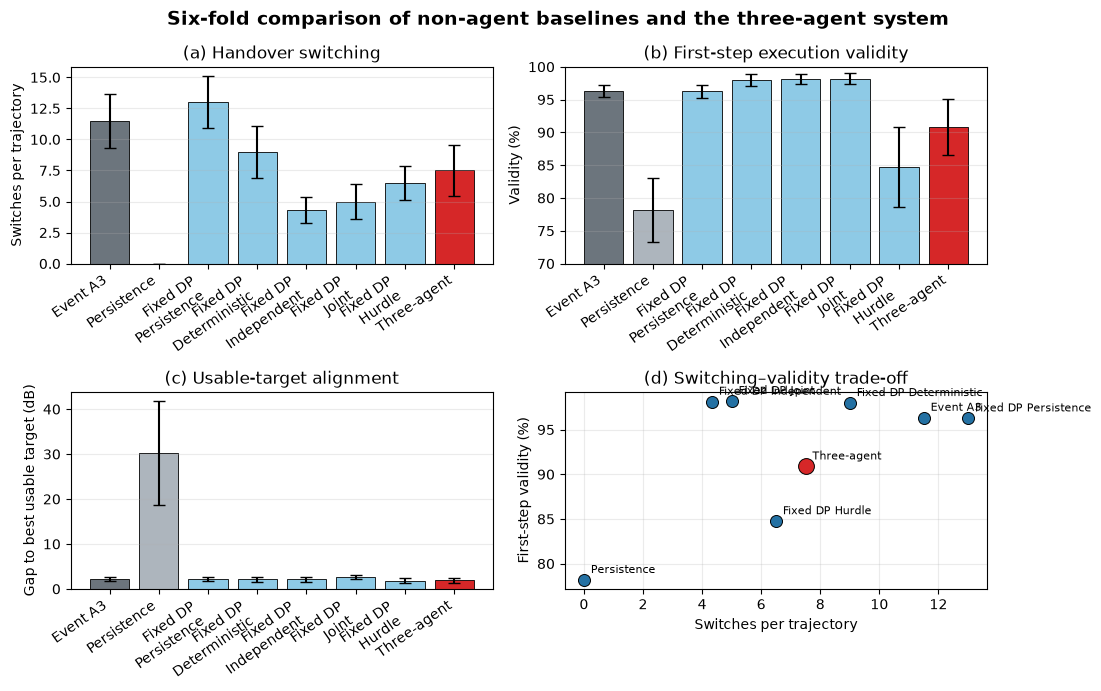

Saved figure to: /home/afanali/wcnc_project/improved_experiment_v2/figures_three_agents/three_agent_benchmark_comparison.pdf


In [11]:
# Cell 11: Publication-style benchmark comparison

import matplotlib.pyplot as plt
import numpy as np

plot_df = benchmark_summary.copy()

labels = [
    "Event A3",
    "Persistence",
    "Fixed DP\nPersistence",
    "Fixed DP\nDeterministic",
    "Fixed DP\nIndependent",
    "Fixed DP\nJoint",
    "Fixed DP\nHurdle",
    "Three-agent",
]

plot_df["label"] = labels

colors = [
    "#6c757d",  # Event A3
    "#adb5bd",  # Persistence
    "#8ecae6",
    "#8ecae6",
    "#8ecae6",
    "#8ecae6",
    "#8ecae6",
    "#d62728",  # Three-agent system
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(11, 7),
)

x = np.arange(len(plot_df))

# (a) Handover count
ax = axes[0, 0]
ax.bar(
    x,
    plot_df["handovers_mean"],
    yerr=plot_df["handovers_std"],
    color=colors,
    capsize=4,
    edgecolor="black",
    linewidth=0.6,
)
ax.set_title("(a) Handover switching")
ax.set_ylabel("Switches per trajectory")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["label"], rotation=35, ha="right")
ax.grid(axis="y", alpha=0.25)

# (b) First-step validity
ax = axes[0, 1]
ax.bar(
    x,
    100 * plot_df["validity_mean"],
    yerr=100 * plot_df["validity_std"],
    color=colors,
    capsize=4,
    edgecolor="black",
    linewidth=0.6,
)
ax.set_title("(b) First-step execution validity")
ax.set_ylabel("Validity (%)")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["label"], rotation=35, ha="right")
ax.set_ylim(70, 100)
ax.grid(axis="y", alpha=0.25)

# (c) Usable-target alignment
ax = axes[1, 0]
ax.bar(
    x,
    plot_df["usable_gap_mean"],
    yerr=plot_df["usable_gap_std"],
    color=colors,
    capsize=4,
    edgecolor="black",
    linewidth=0.6,
)
ax.set_title("(c) Usable-target alignment")
ax.set_ylabel("Gap to best usable target (dB)")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["label"], rotation=35, ha="right")
ax.grid(axis="y", alpha=0.25)

# (d) Handover–validity trade-off
ax = axes[1, 1]

for index, row in plot_df.iterrows():
    marker_size = 130 if row["benchmark"] == "Three-agent system" else 75
    marker_color = "#d62728" if row["benchmark"] == "Three-agent system" else "#2471a3"

    ax.scatter(
        row["handovers_mean"],
        100 * row["validity_mean"],
        s=marker_size,
        color=marker_color,
        edgecolor="black",
        linewidth=0.7,
        zorder=3,
    )

    ax.annotate(
        row["label"].replace("\n", " "),
        (
            row["handovers_mean"],
            100 * row["validity_mean"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

ax.set_title("(d) Switching–validity trade-off")
ax.set_xlabel("Switches per trajectory")
ax.set_ylabel("First-step validity (%)")
ax.grid(alpha=0.25)

fig.suptitle(
    "Six-fold comparison of non-agent baselines and the three-agent system",
    fontsize=14,
    fontweight="bold",
)

fig.tight_layout()

figure_path = FIGURES_DIR / "three_agent_benchmark_comparison.pdf"
fig.savefig(
    figure_path,
    bbox_inches="tight",
    dpi=300,
)

plt.show()

print("Saved figure to:", figure_path)